In [5]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [1]:
# NOTEBOOK 04: XGBOOST SURVIVAL MODEL
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

from IPython.display import display

# Load the prepared training and testing datasets
train_df = pd.read_csv("data/pilot_train_data.csv")
test_df = pd.read_csv("data/pilot_test_data.csv")

# Display dataset information
print("XGBOOST SURVIVAL DATASETS")

print("XGBoost Version:", xgb.__version__)
print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

print("\nTraining Events:")
print(train_df["Event"].value_counts())

print("\nTesting Events:")
print(test_df["Event"].value_counts())

display(train_df.head())



XGBOOST SURVIVAL DATASETS
XGBoost Version: 3.4.1
Training Dataset: (1618, 17)
Testing Dataset: (399, 17)

Training Events:
Event
0    1435
1     183
Name: count, dtype: int64

Testing Events:
Event
0    360
1     39
Name: count, dtype: int64


,Site_ID,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,PAVEMENT_FAMILY,Start_Date,IRI_Baseline_Value,Rutting_Baseline_Value,IRI_Gap_Days,Rutting_Gap_Days,Lower_Years,Upper_Years,Event,Trigger_Type,Review_Required,IRI_Baseline_Review,Rutting_Baseline_Review
0,01-0102,1,0102,1,ACUB,1994-08-25,0.941,5.0,0,140,6.532512,6.995209,1,Rutting,False,False,False
1,01-0103,1,0103,1,ACTB,1996-01-10,0.794,4.0,0,0,9.297741,inf,0,Censored,False,False,False
2,01-0104,1,0104,1,ACTB,1996-01-10,0.593,5.0,0,0,9.297741,inf,0,Censored,False,False,False
3,01-0105,1,0105,1,ACTB,1996-01-10,0.609,6.0,0,0,5.618070,6.012320,1,Rutting,False,False,False
4,01-0106,1,0106,1,ACTB,1994-08-25,0.737,6.0,0,140,10.674880,inf,0,Censored,False,False,False


In [2]:
# 2. PREPARE XGBOOST SURVIVAL DATA
# Select the predictor variables
predictors = [
    "IRI_Baseline_Value",
    "Rutting_Baseline_Value"
]

# Prepare training and testing predictors
X_train = train_df[predictors].copy()
X_test = test_df[predictors].copy()

# Extract survival-time bounds
train_lower = train_df["Lower_Years"].to_numpy()
train_upper = train_df["Upper_Years"].to_numpy()

test_lower = test_df["Lower_Years"].to_numpy()
test_upper = test_df["Upper_Years"].to_numpy()

# Create XGBoost DMatrix datasets
dtrain = xgb.DMatrix(X_train)
dtest = xgb.DMatrix(X_test)

# Set interval-censored survival labels
dtrain.set_float_info("label_lower_bound", train_lower)
dtrain.set_float_info("label_upper_bound", train_upper)

dtest.set_float_info("label_lower_bound", test_lower)
dtest.set_float_info("label_upper_bound", test_upper)

# Display survival-data summary
print("XGBOOST SURVIVAL DATA SUMMARY")

print("Training observations:", dtrain.num_row())
print("Testing observations:", dtest.num_row())

print("\nTraining interval-censored events:",
      np.isfinite(train_upper).sum())

print("Training right-censored observations:",
      np.isinf(train_upper).sum())

print("\nTesting interval-censored events:",
      np.isfinite(test_upper).sum())

print("Testing right-censored observations:",
      np.isinf(test_upper).sum())


XGBOOST SURVIVAL DATA SUMMARY
Training observations: 1618
Testing observations: 399

Training interval-censored events: 183
Training right-censored observations: 1435

Testing interval-censored events: 39
Testing right-censored observations: 360


In [3]:
# 3. TRAIN XGBOOST SURVIVAL MODEL
# Define model parameters
xgb_params = {
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": "normal",
    "aft_loss_distribution_scale": 1.2,
    "tree_method": "hist",
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 1.0,
    "seed": 42
}

# Store training results
training_results = {}

# Train the model
xgb_model = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=100,
    evals=[(dtrain, "train")],
    evals_result=training_results,
    verbose_eval=20
)

# Display training results
print("\nXGBOOST SURVIVAL TRAINING COMPLETED")

print(
    "Final Training NLL:",
    round(training_results["train"]["aft-nloglik"][-1], 4)
)


[0]	train-aft-nloglik:3.15431
[20]	train-aft-nloglik:0.98875
[40]	train-aft-nloglik:0.59065
[60]	train-aft-nloglik:0.51463
[80]	train-aft-nloglik:0.49884
[99]	train-aft-nloglik:0.49369

XGBOOST SURVIVAL TRAINING COMPLETED
Final Training NLL: 0.4937


In [4]:
# 4. EVALUATE XGBOOST SURVIVAL MODEL
# Evaluate model on training data
train_evaluation = xgb_model.eval(
    dtrain, name="train"
)

# Evaluate model on testing data
test_evaluation = xgb_model.eval(
    dtest, name="test"
)

print("XGBOOST SURVIVAL MODEL EVALUATION")

print("\nTraining Results:")
print(train_evaluation)

print("\nTesting Results:")
print(test_evaluation)

# Extract the test negative log-likelihood
xgb_test_nll = float(
    test_evaluation.split(":")[-1]
)

print("\nTESTING DATA SUMMARY")
print("Testing observations:", len(test_df))
print("Interval-censored events:",
      np.isfinite(test_upper).sum())
print("Right-censored observations:",
      np.isinf(test_upper).sum())

print("\nXGBoost Test NLL:",
      round(xgb_test_nll, 4))


XGBOOST SURVIVAL MODEL EVALUATION

Training Results:
[0]	train-aft-nloglik:0.52100229171752022

Testing Results:
[0]	test-aft-nloglik:0.46923397795088423

TESTING DATA SUMMARY
Testing observations: 399
Interval-censored events: 39
Right-censored observations: 360

XGBoost Test NLL: 0.4692


In [5]:
# 5. VERIFY XGBOOST TRAINING RESULTS
# Check the number of boosting rounds
print("XGBOOST MODEL VERIFICATION")

print("Boosting rounds:",
      xgb_model.num_boosted_rounds())

# Retrieve the last training loss recorded during fitting
logged_nll = training_results["train"]["aft-nloglik"][-1]

print("\nLast recorded training NLL:",
      round(logged_nll, 6))

# Re-evaluate the trained model
train_check = xgb_model.eval(dtrain, name="train")
test_check = xgb_model.eval(dtest, name="test")

print("\nRe-evaluated training NLL:")
print(train_check)

print("\nRe-evaluated testing NLL:")
print(test_check)

# Compare both training scores
reevaluated_nll = float(train_check.split(":")[-1])

print("\nTraining results consistent:",
      np.isclose(logged_nll, reevaluated_nll, atol=1e-5))


XGBOOST MODEL VERIFICATION
Boosting rounds: 100

Last recorded training NLL: 0.493687

Re-evaluated training NLL:
[0]	train-aft-nloglik:0.52100229171752022

Re-evaluated testing NLL:
[0]	test-aft-nloglik:0.46923397795088423

Training results consistent: False


In [6]:
# 5A. CORRECT XGBOOST AFT EVALUATION
# Reapply the AFT settings used during training
xgb_model.set_param({
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": "normal",
    "aft_loss_distribution_scale": 1.2
})

# Re-evaluate the model
train_evaluation = xgb_model.eval(dtrain, name="train")
test_evaluation = xgb_model.eval(dtest, name="test")

# Extract evaluation results
train_nll = float(train_evaluation.split(":")[-1])
xgb_test_nll = float(test_evaluation.split(":")[-1])

logged_nll = training_results["train"]["aft-nloglik"][-1]

print("CORRECTED XGBOOST EVALUATION")

print("Recorded Training NLL:", round(logged_nll, 6))
print("Re-evaluated Training NLL:", round(train_nll, 6))
print("Testing NLL:", round(xgb_test_nll, 6))

print("\nTraining results consistent:",
      np.isclose(logged_nll, train_nll, atol=1e-5))


CORRECTED XGBOOST EVALUATION
Recorded Training NLL: 0.493687
Re-evaluated Training NLL: 0.493687
Testing NLL: 0.44969

Training results consistent: True


[0]	train-aft-nloglik:3.14561	validation-aft-nloglik:3.19202
[25]	train-aft-nloglik:0.80643	validation-aft-nloglik:0.88951
[50]	train-aft-nloglik:0.51818	validation-aft-nloglik:0.62214
[75]	train-aft-nloglik:0.47985	validation-aft-nloglik:0.59759
[100]	train-aft-nloglik:0.47063	validation-aft-nloglik:0.59843
[117]	train-aft-nloglik:0.46767	validation-aft-nloglik:0.59710

XGBOOST VALIDATION RESULTS
Training observations: 1314
Validation observations: 304
Training events: 139
Validation events: 44

Best boosting round: 88
Best validation NLL: 0.5966


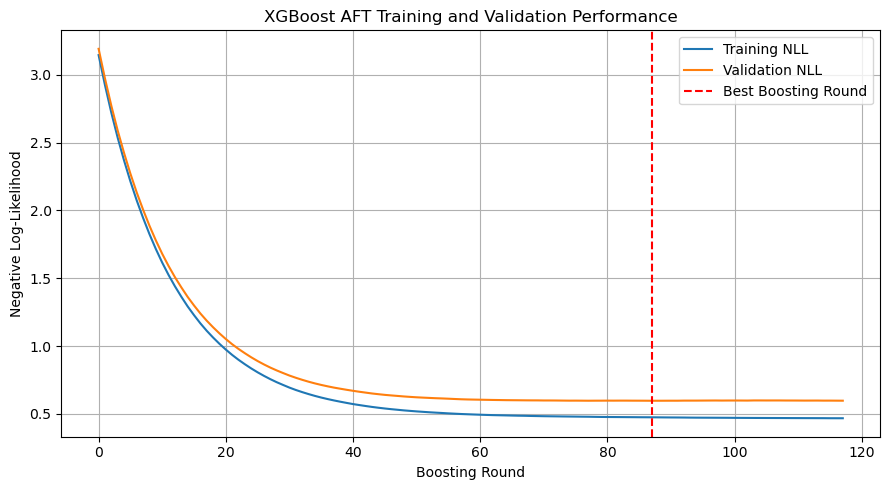

In [7]:

# 6. XGBOOST VALIDATION AND EARLY STOPPING

from sklearn.model_selection import GroupShuffleSplit

# Split the training dataset by physical pavement section
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_df,
        groups=train_df["Site_ID"]
    )
)

# Create training and validation subsets
sub_train = train_df.iloc[train_idx].copy()
validation = train_df.iloc[val_idx].copy()

# Check that pavement sections do not overlap
assert set(sub_train["Site_ID"]).isdisjoint(
    set(validation["Site_ID"])
)

# Create XGBoost datasets
dsubtrain = xgb.DMatrix(sub_train[predictors])
dval = xgb.DMatrix(validation[predictors])

# Add survival-time bounds
dsubtrain.set_float_info(
    "label_lower_bound",
    sub_train["Lower_Years"].to_numpy()
)

dsubtrain.set_float_info(
    "label_upper_bound",
    sub_train["Upper_Years"].to_numpy()
)

dval.set_float_info(
    "label_lower_bound",
    validation["Lower_Years"].to_numpy()
)

dval.set_float_info(
    "label_upper_bound",
    validation["Upper_Years"].to_numpy()
)

# Store the validation results
validation_results = {}

# Train with early stopping
xgb_validation_model = xgb.train(
    params=xgb_params,
    dtrain=dsubtrain,
    num_boost_round=500,
    evals=[
        (dsubtrain, "train"),
        (dval, "validation")
    ],
    evals_result=validation_results,
    early_stopping_rounds=30,
    verbose_eval=25
)

# Display results
print("\nXGBOOST VALIDATION RESULTS")

print("Training observations:", len(sub_train))
print("Validation observations:", len(validation))

print("Training events:", sub_train["Event"].sum())
print("Validation events:", validation["Event"].sum())

print("\nBest boosting round:",
      xgb_validation_model.best_iteration + 1)

print("Best validation NLL:",
      round(xgb_validation_model.best_score, 4))

# Plot the training and validation losses
plt.figure(figsize=(9, 5))

plt.plot(
    validation_results["train"]["aft-nloglik"],
    label="Training NLL"
)

plt.plot(
    validation_results["validation"]["aft-nloglik"],
    label="Validation NLL"
)

plt.axvline(
    xgb_validation_model.best_iteration,
    color="red",
    linestyle="--",
    label="Best Boosting Round"
)

plt.title("XGBoost AFT Training and Validation Performance")
plt.xlabel("Boosting Round")
plt.ylabel("Negative Log-Likelihood")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
# 7. REFIT XGBOOST USING THE BEST BOOSTING ROUND

# Use the best number of rounds from validation
best_rounds = xgb_validation_model.best_iteration + 1

print("Selected boosting rounds:", best_rounds)

# Train using the full training dataset
xgb_final_model = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=best_rounds,
    evals=[(dtrain, "train")],
    verbose_eval=False
)

# Ensure consistent AFT evaluation settings
xgb_final_model.set_param({
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": "normal",
    "aft_loss_distribution_scale": 1.2
})

# Evaluate the refitted model
final_train_eval = xgb_final_model.eval(
    dtrain, name="train"
)

final_test_eval = xgb_final_model.eval(
    dtest, name="test"
)

# Extract NLL values
final_train_nll = float(
    final_train_eval.split(":")[-1]
)

final_test_nll = float(
    final_test_eval.split(":")[-1]
)

# Display model results
print("\nREFITTED XGBOOST SURVIVAL MODEL")

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))
print("Boosting rounds:", best_rounds)

print("\nTraining NLL:", round(final_train_nll, 4))
print("Testing NLL:", round(final_test_nll, 4))

print("\nPrevious pilot XGBoost Test NLL: 0.4497")


Selected boosting rounds: 88

REFITTED XGBOOST SURVIVAL MODEL
Training observations: 1618
Testing observations: 399
Boosting rounds: 88

Training NLL: 0.4967
Testing NLL: 0.45

Previous pilot XGBoost Test NLL: 0.4497


XGBOOST FEATURE IMPORTANCE


,Feature,Importance
1,Rutting_Baseline_Value,14.378094
0,IRI_Baseline_Value,3.606786


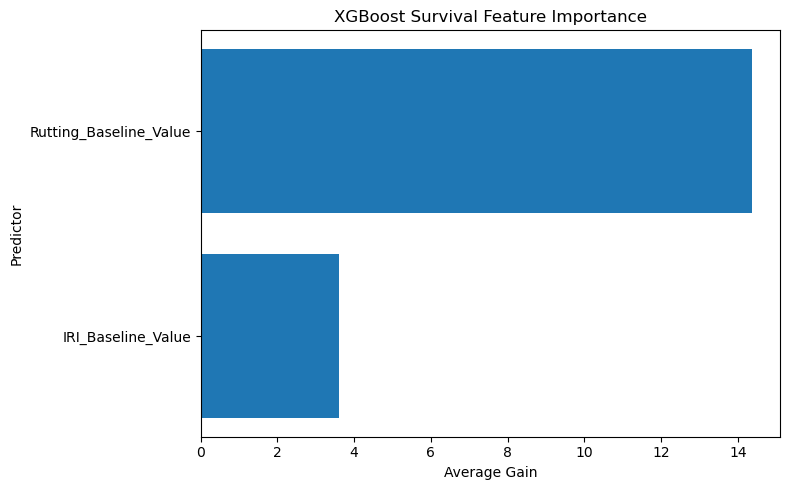

In [9]:
# 8. XGBOOST FEATURE IMPORTANCE
# Extract feature importance using gain
importance = xgb_final_model.get_score(
    importance_type="gain"
)

# Create feature importance table
importance_df = pd.DataFrame(
    list(importance.items()),
    columns=["Feature", "Importance"]
)

# Sort features by importance
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("XGBOOST FEATURE IMPORTANCE")
display(importance_df)

# Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()

plt.title("XGBoost Survival Feature Importance")
plt.xlabel("Average Gain")
plt.ylabel("Predictor")
plt.tight_layout()
plt.show()


In [11]:
# 9. SAVE XGBOOST SURVIVAL MODEL RESULTS

from pathlib import Path

# Create results folder
results_folder = Path("results")
results_folder.mkdir(exist_ok=True)

# Save the trained XGBoost model
xgb_final_model.save_model(
    str(results_folder / "xgboost_aft_pilot.json")
)

# Save feature importance results
importance_df.to_csv(
    results_folder / "xgboost_feature_importance.csv",
    index=False
)

# Create model performance summary
xgb_summary = pd.DataFrame({
    "Model": ["XGBoost AFT"],
    "Training_Observations": [len(train_df)],
    "Testing_Observations": [len(test_df)],
    "Training_Events": [train_df["Event"].sum()],
    "Testing_Events": [test_df["Event"].sum()],
    "Boosting_Rounds": [best_rounds],
    "Training_NLL": [final_train_nll],
    "Testing_NLL": [final_test_nll],
    "AFT_Distribution": [
        xgb_params["aft_loss_distribution"]
    ],
    "AFT_Scale": [
        xgb_params["aft_loss_distribution_scale"]
    ]
})

# performance results
xgb_summary.to_csv(
    results_folder / "xgboost_performance.csv",
    index=False
)

print("XGBOOST MODEL AND RESULTS SAVED")
print("Folder:", results_folder.resolve())

display(xgb_summary.round(4))


XGBOOST MODEL AND RESULTS SAVED
Folder: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\results


,Model,Training_Observations,Testing_Observations,Training_Events,Testing_Events,Boosting_Rounds,Training_NLL,Testing_NLL,AFT_Distribution,AFT_Scale
0,XGBoost AFT,1618,399,183,39,88,0.4967,0.45,normal,1.2
